# Robust Bank Account Fraud Detection Under Temporal Distribution Shift
**BT4012 Fraud Analytics — Group 21**

**Primary question:** How do temporal changes in fraud prevalence and predictive feature relationships affect the future performance of bank account fraud detection models?

**Supporting questions**
1. Which classifier best maintains fraud-detection performance on future applications?
2. How does performance differ under changes in fraud prevalence (Variant IV) compared with changes in feature predictiveness (Variant V)?
3. How do these changes affect false-positive rates and fraud recall for applicants aged ≤50 vs >50?

**Design summary**

| Item | Choice |
|---|---|
| Datasets | Base, Variant IV, Variant V (BAF suite, NeurIPS 2022), each a separate experiment |
| Time split | Train: months 0–3 · Validation: months 4–5 · Out-of-time test: months 6–7 (untouched until evaluation) |
| Models | Logistic regression, decision tree, random forest, LightGBM, XGBoost (class-weighted) |
| Tuning | Hyperparameters chosen on the Base validation period, then fixed for Variants IV and V |
| Ranking metrics | Average precision (AP) **and** recall at 5% FPR (prevalence-independent) |
| Operating settings | **Fixed threshold** (5% FPR on validation, applied unchanged) — primary for the age comparison; **fixed review capacity** (top 1% / 5% of each month) — secondary |

**Data:** download `Base.csv`, `Variant IV.csv` and `Variant V.csv` from the [Kaggle BAF dataset](https://www.kaggle.com/datasets/sgpjesus/bank-account-fraud-dataset-neurips-2022) into the folder set in `DATA_DIR` below.

## 0. Setup

In [ ]:
# Uncomment if the boosting libraries are missing
pip install lightgbm xgboost

  Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl (2.4 MB)

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, time, json, warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

try:
    import lightgbm as lgb
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
    print("lightgbm not installed - LightGBM will be skipped")
try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed - XGBoost will be skipped")

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [3]:
# ---------------- Configuration ----------------
DATA_DIR = "data"            # folder containing the three CSVs
DATASETS = {"Base": "Base.csv", "Variant IV": "Variant IV.csv", "Variant V": "Variant V.csv"}
OUT_DIR = "outputs"

TARGET, MONTH, AGE = "fraud_bool", "month", "customer_age"
AGE_CUTOFF = 50              # groups: <=50 vs >50
INCLUDE_AGE_FEATURE = True   # set False to exclude customer_age from model inputs

TRAIN_MONTHS = [0, 1, 2, 3]
VAL_MONTHS   = [4, 5]
TEST_MONTHS  = [6, 7]

TARGET_FPR = 0.05                    # operating point (as in the BAF paper)
REVIEW_CAPACITIES = [0.01, 0.05]     # share of each month's applications reviewed

SAMPLE_FRAC = None   # e.g. 0.2 for a quick run (stratified by month x label); None = full data
RANDOM_STATE = 42

CAT_COLS = ["payment_type", "employment_status", "housing_status", "source", "device_os"]
# BAF encodes missing values as -1 in these columns ...
MISSING_NEG1 = ["prev_address_months_count", "current_address_months_count", "bank_months_count",
                "session_length_in_minutes", "device_distinct_emails_8w"]
# ... and as any negative value here
MISSING_NEGATIVE = ["intended_balcon_amount"]

os.makedirs(OUT_DIR, exist_ok=True)

## 1. Load data
Missing-value sentinels are converted to `NaN` so they can be imputed and flagged. Numeric columns are downcast to save memory (3 × 1M rows).

In [4]:
def load_dataset(name):
    df = pd.read_csv(os.path.join(DATA_DIR, DATASETS[name]))
    if SAMPLE_FRAC:
        df = df.groupby([MONTH, TARGET], group_keys=False).sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE)
        df = df.sort_index()
    for c in df.select_dtypes("float64").columns:
        df[c] = df[c].astype("float32")
    for c in df.select_dtypes("int64").columns:
        df[c] = pd.to_numeric(df[c], downcast="integer")
    for c in MISSING_NEG1:
        df[c] = df[c].where(df[c] != -1, np.nan).astype("float32")
    for c in MISSING_NEGATIVE:
        df[c] = df[c].where(df[c] >= 0, np.nan).astype("float32")
    df["age_group"] = np.where(df[AGE] > AGE_CUTOFF, ">50", "<=50")
    df["split"] = np.select([df[MONTH].isin(TRAIN_MONTHS), df[MONTH].isin(VAL_MONTHS)],
                            ["train", "val"], default="test")
    return df.reset_index(drop=True)

data = {name: load_dataset(name) for name in DATASETS}
for name, df in data.items():
    print(f"{name:11s} rows={len(df):,}  cols={df.shape[1]}  fraud rate={df[TARGET].mean():.4%}")

Base        rows=1,000,000  cols=34  fraud rate=1.1029%
Variant IV  rows=1,000,000  cols=34  fraud rate=1.1030%
Variant V   rows=1,000,000  cols=36  fraud rate=1.1030%


## 2. Exploratory analysis
### 2.1 Overview and class imbalance

In [5]:
overview = pd.DataFrame({
    name: {"rows": len(df), "frauds": int(df[TARGET].sum()), "fraud_rate": df[TARGET].mean(),
           "share_age_>50": (df["age_group"] == ">50").mean(),
           "train_rows": (df.split == "train").sum(), "val_rows": (df.split == "val").sum(),
           "test_rows": (df.split == "test").sum()}
    for name, df in data.items()}).T
display(overview)

,rows,frauds,fraud_rate,share_age_>50,train_rows,val_rows,test_rows
Base,1000000.0000,11029.0000,0.0110,0.0427,547975.0000,247014.0000,205011.0000
Variant IV,1000000.0000,11030.0000,0.0110,0.1230,484462.0000,273866.0000,241672.0000
Variant V,1000000.0000,11030.0000,0.0110,0.1227,484464.0000,273864.0000,241672.0000


In [6]:
missing = pd.DataFrame({name: df[MISSING_NEG1 + MISSING_NEGATIVE].isna().mean() for name, df in data.items()})
print("Share of missing (sentinel-coded) values")
display(missing)

const_cols = {name: [c for c in df.columns if df[c].nunique(dropna=False) <= 1] for name, df in data.items()}
print("Constant columns:", const_cols)

Share of missing (sentinel-coded) values


,Base,Variant IV,Variant V
prev_address_months_count,0.7129,0.7618,0.7617
current_address_months_count,0.0043,0.0035,0.0034
bank_months_count,0.2536,0.2472,0.2469
session_length_in_minutes,0.0020,0.0023,0.0022
device_distinct_emails_8w,0.0004,0.0003,0.0003
intended_balcon_amount,0.7425,0.7517,0.7511


Constant columns: {'Base': ['device_fraud_count'], 'Variant IV': ['device_fraud_count'], 'Variant V': ['device_fraud_count']}


### 2.2 Monthly fraud prevalence, overall and by age group
This is where Variant IV should differ: group-specific prevalence in months 0–5, similar prevalence in months 6–7.

age_group   <=50                         >50                      overall  \
dataset     Base Variant IV Variant V   Base Variant IV Variant V    Base   
month                                                                       
0         0.0101     0.0093    0.0109 0.0360     0.0282    0.0172  0.0113   
1         0.0086     0.0072    0.0083 0.0268     0.0209    0.0134  0.0094   
2         0.0079     0.0060    0.0067 0.0289     0.0177    0.0120  0.0087   
3         0.0082     0.0110    0.0128 0.0312     0.0329    0.0198  0.0092   
4         0.0101     0.0129    0.0150 0.0376     0.0348    0.0203  0.0114   
5         0.0109     0.0071    0.0085 0.0340     0.0230    0.0136  0.0118   
6         0.0122     0.0115    0.0114 0.0382     0.0172    0.0181  0.0134   
7         0.0135     0.0087    0.0086 0.0551     0.0139    0.0142  0.0147   

age_group                       
dataset   Variant IV Variant V  
month                           
0             0.0117    0.0117  
1             0.0089    0.0089  
2             0.0073    0.0073  
3             0.0136    0.0136  
4             0.0157    0.0157  
5             0.0091    0.0091  
6             0.0123    0.0123  
7             0.0093    0.0093

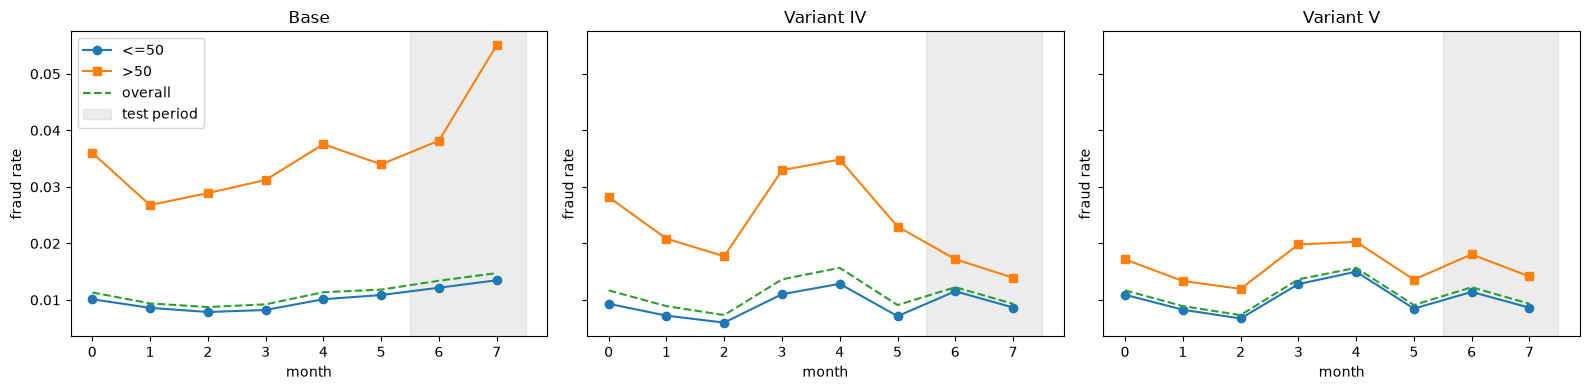

In [7]:
prev = (pd.concat([df.assign(dataset=name) for name, df in data.items()])
          .groupby(["dataset", MONTH, "age_group"], observed=True)[TARGET].mean()
          .unstack("age_group"))
prev["overall"] = pd.concat([df.assign(dataset=name) for name, df in data.items()]).groupby(["dataset", MONTH])[TARGET].mean()
display(prev.unstack("dataset").round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, DATASETS):
    p = prev.loc[name]
    for col, style in [("<=50", "-o"), (">50", "-s"), ("overall", "--")]:
        ax.plot(p.index, p[col], style, label=col)
    ax.axvspan(min(TEST_MONTHS) - 0.5, max(TEST_MONTHS) + 0.5, color="grey", alpha=0.15, label="test period")
    ax.set(title=name, xlabel="month", ylabel="fraud rate")
axes[0].legend()
plt.tight_layout(); plt.show()

### 2.3 Feature distributions (Base, fraud vs non-fraud)

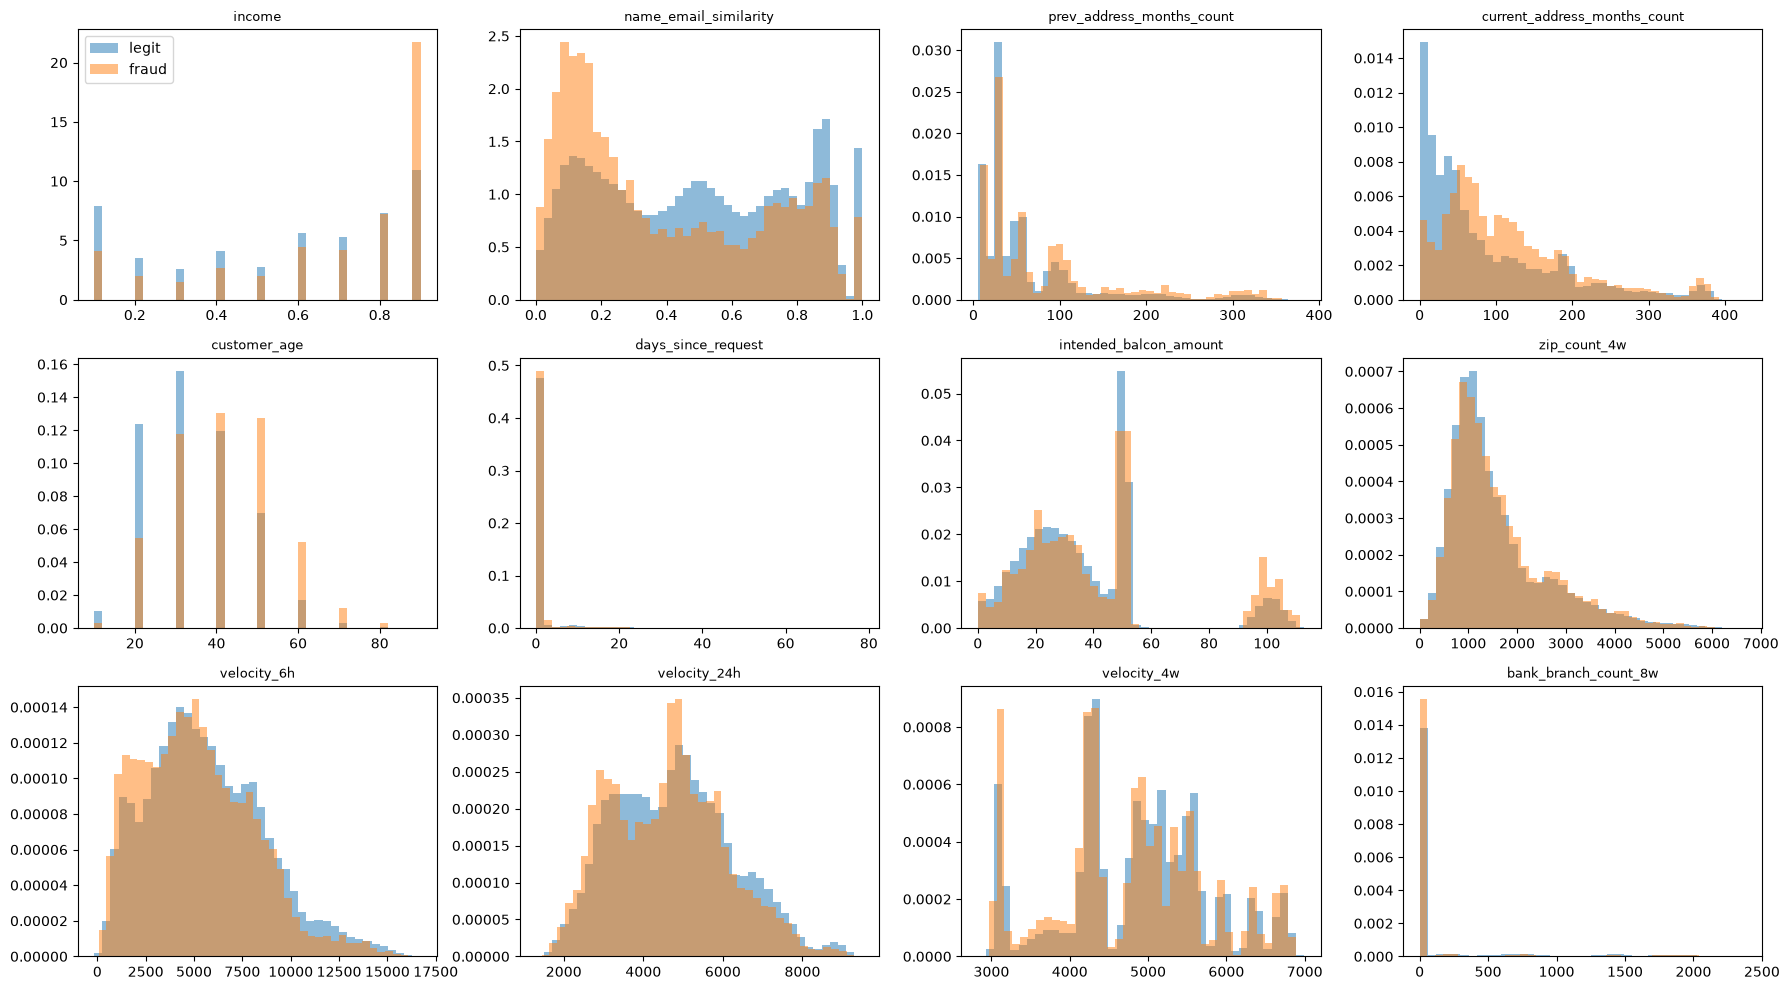

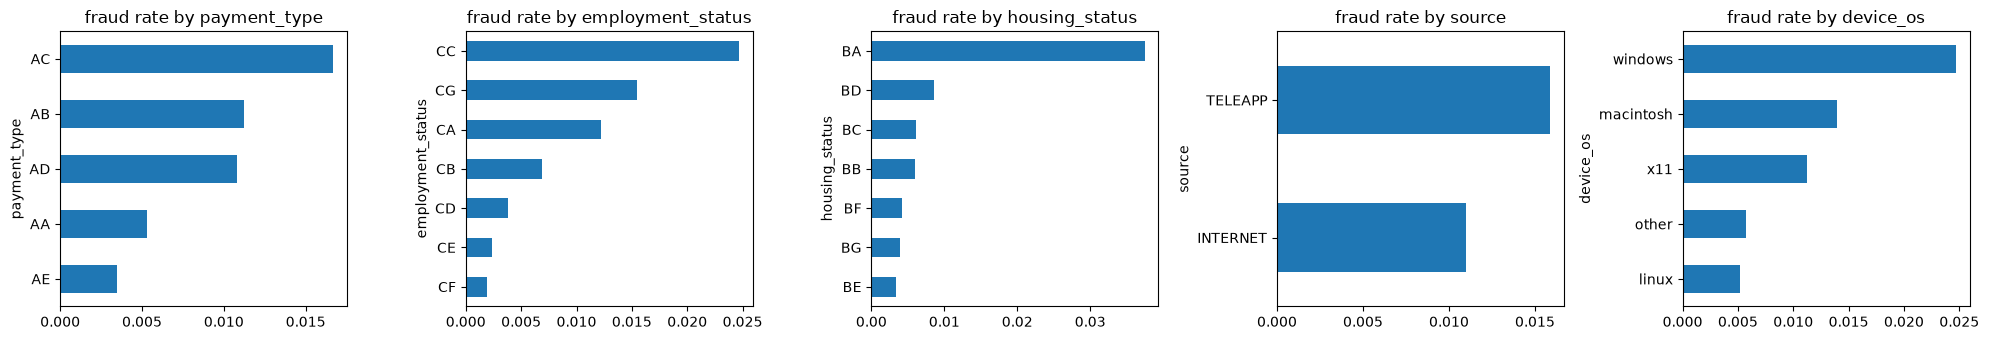

In [8]:
base = data["Base"]
num_cols_all = [c for c in base.columns if c not in CAT_COLS + [TARGET, MONTH, "age_group", "split"]
                and base[c].nunique() > 2]
show = num_cols_all[:12]
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, c in zip(axes.ravel(), show):
    for lbl, name in [(0, "legit"), (1, "fraud")]:
        v = base.loc[base[TARGET] == lbl, c].dropna()
        ax.hist(v, bins=40, density=True, alpha=0.5, label=name)
    ax.set_title(c, fontsize=9)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(CAT_COLS), figsize=(20, 3.5))
for ax, c in zip(axes, CAT_COLS):
    base.groupby(c)[TARGET].mean().sort_values().plot.barh(ax=ax)
    ax.set(title=f"fraud rate by {c}", xlabel="")
plt.tight_layout(); plt.show()

## 3. Preprocessing and models
* Features: all columns except the label, month and helper columns; columns constant in the **training** months are dropped.
* Numerical: median imputation + missing-indicator columns; standard scaling for logistic regression only.
* Categorical: one-hot encoding (unseen categories ignored).
* All preprocessing is fitted on training months only, inside an sklearn `Pipeline`.
* Class imbalance: class weighting (`balanced` / `scale_pos_weight`); validation and test data keep their natural distribution.

In [9]:
def feature_lists(train_df):
    feats = [c for c in train_df.columns if c not in (TARGET, MONTH, "age_group", "split")]
    if not INCLUDE_AGE_FEATURE:
        feats.remove(AGE)
    feats = [c for c in feats if train_df[c].nunique(dropna=False) > 1]
    cats = [c for c in feats if c in CAT_COLS]
    nums = [c for c in feats if c not in CAT_COLS]
    return feats, cats, nums

def make_preprocessor(cats, nums, scale):
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer(
        [("num", Pipeline(num_steps), nums),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats)])

def make_model(name, params, pos_weight):
    # returns (estimator, needs_scaling)
    if name == "Logistic Regression":
        return LogisticRegression(class_weight="balanced", max_iter=2000, **params), True
    if name == "Decision Tree":
        return DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, **params), False
    if name == "Random Forest":
        return RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1,
                                      random_state=RANDOM_STATE, **params), False
    if name == "LightGBM":
        return lgb.LGBMClassifier(scale_pos_weight=pos_weight, random_state=RANDOM_STATE,
                                  n_jobs=-1, verbose=-1, **params), False
    if name == "XGBoost":
        return xgb.XGBClassifier(scale_pos_weight=pos_weight, tree_method="hist", eval_metric="aucpr",
                                 random_state=RANDOM_STATE, n_jobs=-1, **params), False
    raise ValueError(name)

def fit_pipeline(train_df, model_name, params):
    feats, cats, nums = feature_lists(train_df)
    y = train_df[TARGET]
    pos_weight = (y == 0).sum() / max((y == 1).sum(), 1)
    clf, scale = make_model(model_name, params, pos_weight)
    pipe = Pipeline([("prep", make_preprocessor(cats, nums, scale)), ("clf", clf)])
    pipe.fit(train_df[feats], y)
    return pipe, feats

MODEL_NAMES = ["Logistic Regression", "Decision Tree", "Random Forest"]
if HAS_LGBM: MODEL_NAMES.append("LightGBM")
if HAS_XGB:  MODEL_NAMES.append("XGBoost")
print(MODEL_NAMES)

['Logistic Regression', 'Decision Tree', 'Random Forest', 'LightGBM', 'XGBoost']


## 4. Hyperparameter selection (Base development period only)
Each candidate is trained on months 0–3 and scored by validation AP on months 4–5. The best setting per model is then **fixed** for all three datasets, so Variants IV and V act as genuine stress tests. The grids are deliberately small; widen them if compute allows.

In [10]:
PARAM_GRIDS = {
    "Logistic Regression": {"C": [0.01, 0.1, 1.0]},
    "Decision Tree": {"max_depth": [4, 6, 8, 10], "min_samples_leaf": [100, 500]},
    "Random Forest": {"n_estimators": [200], "max_depth": [8, 12, None],
                      "min_samples_leaf": [50, 200], "max_samples": [0.25]},
    "LightGBM": {"n_estimators": [500], "learning_rate": [0.03, 0.1], "num_leaves": [31, 63],
                 "min_child_samples": [100], "subsample": [0.8], "subsample_freq": [1],
                 "colsample_bytree": [0.8]},
    "XGBoost": {"n_estimators": [500], "learning_rate": [0.03, 0.1], "max_depth": [4, 6],
                "min_child_weight": [5], "subsample": [0.8], "colsample_bytree": [0.8]},
}

base_tr = data["Base"][data["Base"].split == "train"]
base_va = data["Base"][data["Base"].split == "val"]

tune_rows, best_params = [], {}
for m in MODEL_NAMES:
    keys = list(PARAM_GRIDS[m])
    for values in product(*PARAM_GRIDS[m].values()):
        params = dict(zip(keys, values))
        t0 = time.time()
        pipe, feats = fit_pipeline(base_tr, m, params)
        ap = average_precision_score(base_va[TARGET], pipe.predict_proba(base_va[feats])[:, 1])
        tune_rows.append({"model": m, "params": json.dumps(params), "val_AP": ap, "secs": time.time() - t0})
        print(f"{m:20s} {params}  val AP={ap:.4f}  ({time.time() - t0:.0f}s)")
    best = max((r for r in tune_rows if r["model"] == m), key=lambda r: r["val_AP"])
    best_params[m] = json.loads(best["params"])

tuning = pd.DataFrame(tune_rows)
tuning.to_csv(f"{OUT_DIR}/tuning_results.csv", index=False)
print("\nSelected hyperparameters:")
for m, p in best_params.items():
    print(f"  {m}: {p}")

Logistic Regression  {'C': 0.01}  val AP=0.1442  (3s)
Logistic Regression  {'C': 0.1}  val AP=0.1441  (3s)
Logistic Regression  {'C': 1.0}  val AP=0.1441  (3s)
Decision Tree        {'max_depth': 4, 'min_samples_leaf': 100}  val AP=0.0538  (5s)
Decision Tree        {'max_depth': 4, 'min_samples_leaf': 500}  val AP=0.0538  (5s)
Decision Tree        {'max_depth': 6, 'min_samples_leaf': 100}  val AP=0.0744  (6s)
Decision Tree        {'max_depth': 6, 'min_samples_leaf': 500}  val AP=0.0747  (6s)
Decision Tree        {'max_depth': 8, 'min_samples_leaf': 100}  val AP=0.0824  (7s)
Decision Tree        {'max_depth': 8, 'min_samples_leaf': 500}  val AP=0.0905  (7s)
Decision Tree        {'max_depth': 10, 'min_samples_leaf': 100}  val AP=0.0876  (7s)
Decision Tree        {'max_depth': 10, 'min_samples_leaf': 500}  val AP=0.0945  (7s)
Random Forest        {'n_estimators': 200, 'max_depth': 8, 'min_samples_leaf': 50, 'max_samples': 0.25}  val AP=0.1328  (11s)
Random Forest        {'n_estimators': 20

## 5. Train on each dataset and score validation + test months
For each dataset, every model is trained on months 0–3 with the fixed hyperparameters and scores months 4–7. The validation scores (months 4–5) set the operating threshold; the test scores (months 6–7) are used only for evaluation.

In [11]:
pred_frames, fitted = [], {}
for ds, df in data.items():
    tr = df[df.split == "train"]
    ev = df[df.split != "train"]
    for m in MODEL_NAMES:
        t0 = time.time()
        pipe, feats = fit_pipeline(tr, m, best_params[m])
        fitted[(ds, m)] = (pipe, feats)
        pred_frames.append(pd.DataFrame({
            "dataset": ds, "model": m, "row": ev.index, "month": ev[MONTH].values,
            "split": ev.split.values, "y": ev[TARGET].values,
            "score": pipe.predict_proba(ev[feats])[:, 1], "age_group": ev.age_group.values}))
        print(f"{ds:11s} {m:20s} done ({time.time() - t0:.0f}s)")

preds = pd.concat(pred_frames, ignore_index=True)
# Tie-break copy of the score for thresholds and top-k rules: trees (esp. the decision tree) give many
# identical scores, so a cut-off can fall inside a tied block. A tiny random jitter flags a random part
# of that block instead of all or none of it. AP and PR curves use the raw score.
_rng = np.random.default_rng(RANDOM_STATE)
preds["score_tb"] = preds.score + _rng.uniform(0, 1e-9, len(preds))
preds.head()

Base        Logistic Regression  done (3s)
Base        Decision Tree        done (7s)
Base        Random Forest        done (13s)
Base        LightGBM             done (12s)
Base        XGBoost              done (9s)
Variant IV  Logistic Regression  done (3s)
Variant IV  Decision Tree        done (6s)
Variant IV  Random Forest        done (12s)
Variant IV  LightGBM             done (11s)
Variant IV  XGBoost              done (8s)
Variant V   Logistic Regression  done (4s)
Variant V   Decision Tree        done (8s)
Variant V   Random Forest        done (13s)
Variant V   LightGBM             done (12s)
Variant V   XGBoost              done (8s)


,dataset,model,row,month,split,y,score,age_group,score_tb
0,Base,Logistic Regression,547975,4,val,0,0.1770,<=50,0.1770
1,Base,Logistic Regression,547976,4,val,0,0.8237,<=50,0.8237
2,Base,Logistic Regression,547977,4,val,0,0.0328,<=50,0.0328
3,Base,Logistic Regression,547978,4,val,0,0.8686,<=50,0.8686
4,Base,Logistic Regression,547979,4,val,0,0.0603,<=50,0.0603


## 6. Evaluation helpers
* **AP** depends on fraud prevalence, so a fall in AP can come from a prevalence change alone.
* **Recall at 5% FPR (self-calibrated)** uses the threshold that gives 5% FPR *on the evaluated set itself*. TPR is computed only among frauds and FPR only among legitimate applications, so this metric does not depend on prevalence and measures pure separability.
* **Fixed threshold:** the threshold that gives 5% FPR on validation is applied unchanged; the share of applications flagged can drift.
* **Fixed capacity:** the top *k*% of each month's scores are flagged (no labels needed); the workload is constant and the threshold moves.

In [12]:
def threshold_at_fpr(y, s, fpr):
    return np.quantile(s[y == 0], 1 - fpr)

def recall_at_fpr(y, s, fpr=TARGET_FPR):
    thr = threshold_at_fpr(y, s, fpr)
    return (s[y == 1] > thr).mean()

def summarise(df, flag_col, by):
    # recall, FPR, precision and alert rate for a boolean flag column, grouped by `by`
    f, y = df[flag_col].values, df["y"].values
    g = pd.DataFrame({k: df[k].values for k in by})
    g["tp"], g["fp"] = f & (y == 1), f & (y == 0)
    g["pos"], g["neg"], g["flag"] = y == 1, y == 0, f
    agg = g.groupby(by, observed=True)[["tp", "fp", "pos", "neg", "flag"]].sum()
    n = g.groupby(by, observed=True).size()
    return pd.DataFrame({
        "recall": agg.tp / agg.pos.replace(0, np.nan),
        "FPR": agg.fp / agg.neg,
        "precision": agg.tp / agg.flag.replace(0, np.nan),
        "alert_rate": agg.flag / n,
        "n": n, "frauds": agg.pos}).reset_index()

def age_gap(summary, by):
    # pivot an age-group summary into side-by-side columns plus ratios (>50 relative to <=50)
    w = summary.pivot_table(index=by, columns="age_group", values=["FPR", "recall"])
    w.columns = [f"{a}_{b}" for a, b in w.columns]
    w["FPR_ratio_>50/<=50"] = w["FPR_>50"] / w["FPR_<=50"]
    w["recall_diff_>50-<=50"] = w["recall_>50"] - w["recall_<=50"]
    return w

## 7. Ranking performance: AP vs recall at 5% FPR
If AP falls but recall at 5% FPR is stable, the drop is mostly a prevalence effect. If both fall, the model has genuinely lost its ability to separate fraud from legitimate applications.

In [13]:
def ranking_metrics(df, by):
    rows = []
    for keys, g in df.groupby(by, observed=True):
        y = g.y.values
        rows.append(dict(zip(by, keys if isinstance(keys, tuple) else (keys,)),
                         prevalence=y.mean(), AP=average_precision_score(y, g.score.values),
                         **{"recall@5%FPR": recall_at_fpr(y, g.score_tb.values)}))
    return pd.DataFrame(rows)

rank_period = ranking_metrics(preds, ["dataset", "model", "split"])
rank_month  = ranking_metrics(preds, ["dataset", "model", "month"])

robust = rank_period.pivot_table(index=["dataset", "model"], columns="split",
                                 values=["AP", "recall@5%FPR", "prevalence"])
robust.columns = [f"{a}_{b}" for a, b in robust.columns]
robust["AP_change"] = robust["AP_test"] - robust["AP_val"]
robust["recall@5%FPR_change"] = robust["recall@5%FPR_test"] - robust["recall@5%FPR_val"]
robust = robust[["prevalence_val", "prevalence_test", "AP_val", "AP_test", "AP_change",
                 "recall@5%FPR_val", "recall@5%FPR_test", "recall@5%FPR_change"]]
display(robust)
robust.to_csv(f"{OUT_DIR}/ranking_val_vs_test.csv")

prevalence_val  prevalence_test  AP_val  \
dataset    model                                                          
Base       Decision Tree                0.0116           0.0140  0.0945   
           LightGBM                     0.0116           0.0140  0.1820   
           Logistic Regression          0.0116           0.0140  0.1442   
           Random Forest                0.0116           0.0140  0.1426   
           XGBoost                      0.0116           0.0140  0.1852   
Variant IV Decision Tree                0.0121           0.0110  0.1005   
           LightGBM                     0.0121           0.0110  0.1913   
           Logistic Regression          0.0121           0.0110  0.1600   
           Random Forest                0.0121           0.0110  0.1582   
           XGBoost                      0.0121           0.0110  0.1969   
Variant V  Decision Tree                0.0121           0.0110  0.3923   
           LightGBM                     0.0121           0.0110  0.5507   
           Logistic Regression          0.0121           0.0110  0.3441   
           Random Forest                0.0121           0.0110  0.4902   
           XGBoost                      0.0121           0.0110  0.5544   

                                AP_test  AP_change  recall@5%FPR_val  \
dataset    model                                                       
Base       Decision Tree         0.1050     0.0105            0.4156   
           LightGBM              0.1827     0.0007            0.5522   
           Logistic Regression   0.1585     0.0143            0.5194   
           Random Forest         0.1615     0.0189            0.5082   
           XGBoost               0.1928     0.0076            0.5529   
Variant IV Decision Tree         0.0588    -0.0417            0.4203   
           LightGBM              0.1086    -0.0827            0.5584   
           Logistic Regression   0.0943    -0.0657            0.5187   
           Random Forest         0.0853    -0.0729            0.5135   
           XGBoost               0.1154    -0.0815            0.5713   
Variant V  Decision Tree         0.0396    -0.3527            0.6402   
           LightGBM              0.0649    -0.4858            0.7560   
           Logistic Regression   0.0693    -0.2748            0.6369   
           Random Forest         0.0730    -0.4172            0.7184   
           XGBoost               0.0740    -0.4804            0.7656   

                                recall@5%FPR_test  recall@5%FPR_change  
dataset    model                                                        
Base       Decision Tree                   0.4135              -0.0022  
           LightGBM                        0.5316              -0.0206  
           Logistic Regression             0.5007              -0.0187  
           Random Forest                   0.5122               0.0040  
           XGBoost                         0.5424              -0.0105  
Variant IV Decision Tree                   0.2986              -0.1216  
           LightGBM                        0.4253              -0.1330  
           Logistic Regression             0.4069              -0.1118  
           Random Forest                   0.3801              -0.1334  
           XGBoost                         0.4446              -0.1267  
Variant V  Decision Tree                   0.2892              -0.3510  
           LightGBM                        0.3314              -0.4246  
           Logistic Regression             0.3480              -0.2888  
           Random Forest                   0.3556              -0.3628  
           XGBoost                         0.3439              -0.4218

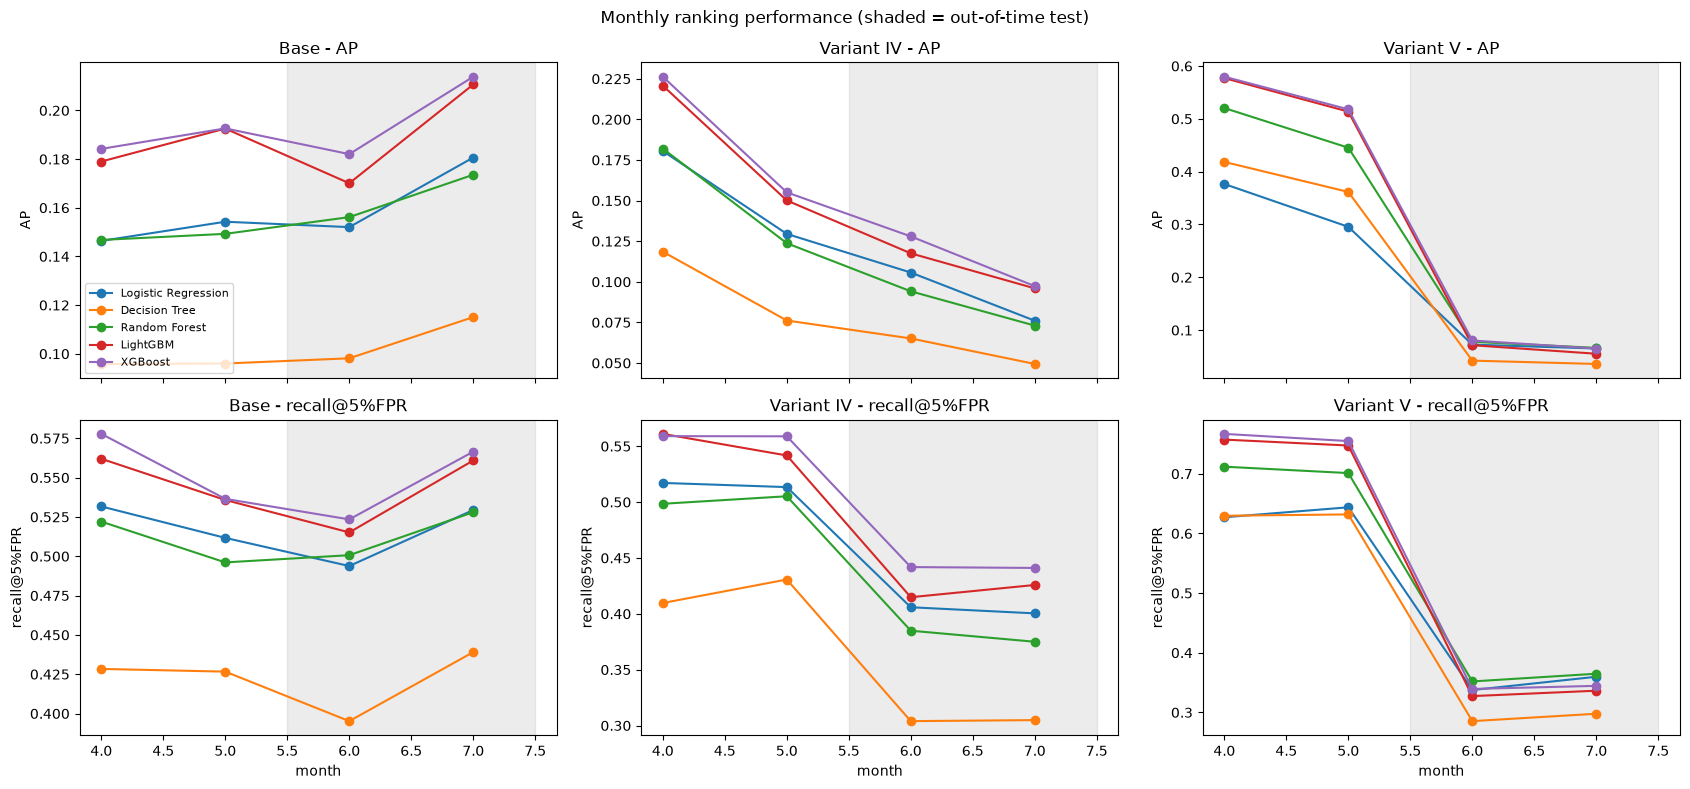

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
for j, ds in enumerate(DATASETS):
    for i, metric in enumerate(["AP", "recall@5%FPR"]):
        ax = axes[i, j]
        for m in MODEL_NAMES:
            r = rank_month[(rank_month.dataset == ds) & (rank_month.model == m)]
            ax.plot(r.month, r[metric], "-o", label=m)
        ax.axvspan(min(TEST_MONTHS) - 0.5, max(TEST_MONTHS) + 0.5, color="grey", alpha=0.15)
        ax.set(title=f"{ds} - {metric}", xlabel="month" if i else "", ylabel=metric)
axes[0, 0].legend(fontsize=8)
plt.suptitle("Monthly ranking performance (shaded = out-of-time test)")
plt.tight_layout(); plt.show()

In [15]:
# Q1/Q2: robustness relative to Base - how much more does each model degrade under each shift?
chg = robust[["AP_change", "recall@5%FPR_change"]].unstack("dataset")
for v in ["Variant IV", "Variant V"]:
    for met in ["AP_change", "recall@5%FPR_change"]:
        chg[(met, f"{v} - Base")] = chg[(met, v)] - chg[(met, "Base")]
display(chg.sort_index(axis=1))

AP_change                                         \
dataset                  Base Variant IV Variant IV - Base Variant V   
model                                                                  
Decision Tree          0.0105    -0.0417           -0.0522   -0.3527   
LightGBM               0.0007    -0.0827           -0.0834   -0.4858   
Logistic Regression    0.0143    -0.0657           -0.0799   -0.2748   
Random Forest          0.0189    -0.0729           -0.0918   -0.4172   
XGBoost                0.0076    -0.0815           -0.0891   -0.4804   

                                     recall@5%FPR_change             \
dataset             Variant V - Base                Base Variant IV   
model                                                                 
Decision Tree                -0.3633             -0.0022    -0.1216   
LightGBM                     -0.4865             -0.0206    -0.1330   
Logistic Regression          -0.2890             -0.0187    -0.1118   
Random Forest                -0.4361              0.0040    -0.1334   
XGBoost                      -0.4880             -0.0105    -0.1267   

                                                                  
dataset             Variant IV - Base Variant V Variant V - Base  
model                                                             
Decision Tree                 -0.1195   -0.3510          -0.3488  
LightGBM                      -0.1124   -0.4246          -0.4040  
Logistic Regression           -0.0931   -0.2888          -0.2702  
Random Forest                 -0.1374   -0.3628          -0.3668  
XGBoost                       -0.1162   -0.4218          -0.4112

### 7.1 Precision–recall curves and best model
The "best" model for the detailed plots below is the one with the highest **Base validation AP**, so it is chosen without looking at test data.

Model selected on Base validation AP: XGBoost


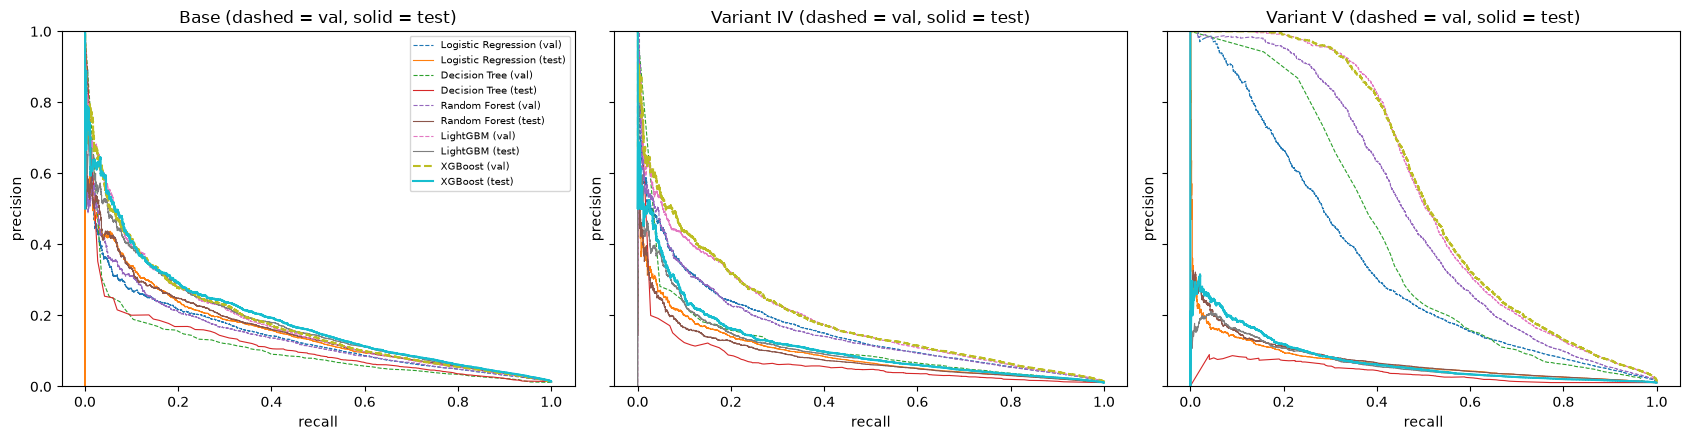

In [16]:
BEST = (rank_period[(rank_period.dataset == "Base") & (rank_period.split == "val")]
        .sort_values("AP", ascending=False).model.iloc[0])
print("Model selected on Base validation AP:", BEST)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, ds in zip(axes, DATASETS):
    for m in MODEL_NAMES:
        for sp, ls in [("val", "--"), ("test", "-")]:
            g = preds[(preds.dataset == ds) & (preds.model == m) & (preds.split == sp)]
            p, r, _ = precision_recall_curve(g.y, g.score)
            ax.plot(r, p, ls, lw=1.5 if m == BEST else 0.8, label=f"{m} ({sp})" if ds == "Base" else None)
    ax.set(title=f"{ds} (dashed = val, solid = test)", xlabel="recall", ylabel="precision", ylim=(0, 1))
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. Operating setting A — fixed threshold (primary)
The threshold giving 5% FPR on the validation months is applied unchanged to each test month. Because the threshold is fixed, the alert rate (share of applications sent for review) can drift.

In [17]:
thr = {(ds, m): threshold_at_fpr(g.y.values, g.score_tb.values, TARGET_FPR)
       for (ds, m), g in preds[preds.split == "val"].groupby(["dataset", "model"])}
thr_df = pd.Series(thr, name="thr").rename_axis(["dataset", "model"]).reset_index()
preds = preds.drop(columns="thr", errors="ignore").merge(thr_df, on=["dataset", "model"])
preds["flag_thr"] = preds.score_tb > preds.thr

thr_period = summarise(preds, "flag_thr", ["dataset", "model", "split"])
thr_month  = summarise(preds, "flag_thr", ["dataset", "model", "month"])
display(thr_period.pivot_table(index=["dataset", "model"], columns="split",
                               values=["recall", "FPR", "precision", "alert_rate"]))
thr_period.to_csv(f"{OUT_DIR}/fixed_threshold_period.csv", index=False)
thr_month.to_csv(f"{OUT_DIR}/fixed_threshold_month.csv", index=False)

FPR        alert_rate        precision  \
split                            test    val       test    val      test   
dataset    model                                                           
Base       Decision Tree       0.0436 0.0500     0.0484 0.0542    0.1113   
           LightGBM            0.0368 0.0500     0.0428 0.0558    0.1519   
           Logistic Regression 0.0314 0.0500     0.0366 0.0554    0.1557   
           Random Forest       0.0373 0.0500     0.0430 0.0553    0.1457   
           XGBoost             0.0388 0.0500     0.0452 0.0558    0.1535   
Variant IV Decision Tree       0.0477 0.0500     0.0504 0.0545    0.0639   
           LightGBM            0.0454 0.0500     0.0493 0.0562    0.0898   
           Logistic Regression 0.0380 0.0500     0.0415 0.0557    0.0948   
           Random Forest       0.0440 0.0500     0.0474 0.0556    0.0819   
           XGBoost             0.0474 0.0500     0.0517 0.0563    0.0920   
Variant V  Decision Tree       0.0479 0.0500     0.0505 0.0572    0.0625   
           LightGBM            0.0433 0.0500     0.0463 0.0586    0.0741   
           Logistic Regression 0.0374 0.0500     0.0402 0.0571    0.0786   
           Random Forest       0.0439 0.0500     0.0471 0.0581    0.0772   
           XGBoost             0.0431 0.0500     0.0461 0.0587    0.0764   

                                      recall         
split                             val   test    val  
dataset    model                                     
Base       Decision Tree       0.0888 0.3836 0.4156  
           LightGBM            0.1147 0.4628 0.5522  
           Logistic Regression 0.1086 0.4062 0.5194  
           Random Forest       0.1065 0.4465 0.5082  
           XGBoost             0.1148 0.4941 0.5529  
Variant IV Decision Tree       0.0936 0.2937 0.4203  
           LightGBM            0.1206 0.4038 0.5584  
           Logistic Regression 0.1130 0.3582 0.5187  
           Random Forest       0.1120 0.3541 0.5135  
           XGBoost             0.1231 0.4333 0.5713  
Variant V  Decision Tree       0.1359 0.2877 0.6402  
           LightGBM            0.1567 0.3126 0.7560  
           Logistic Regression 0.1353 0.2877 0.6369  
           Random Forest       0.1500 0.3311 0.7184  
           XGBoost             0.1583 0.3213 0.7656

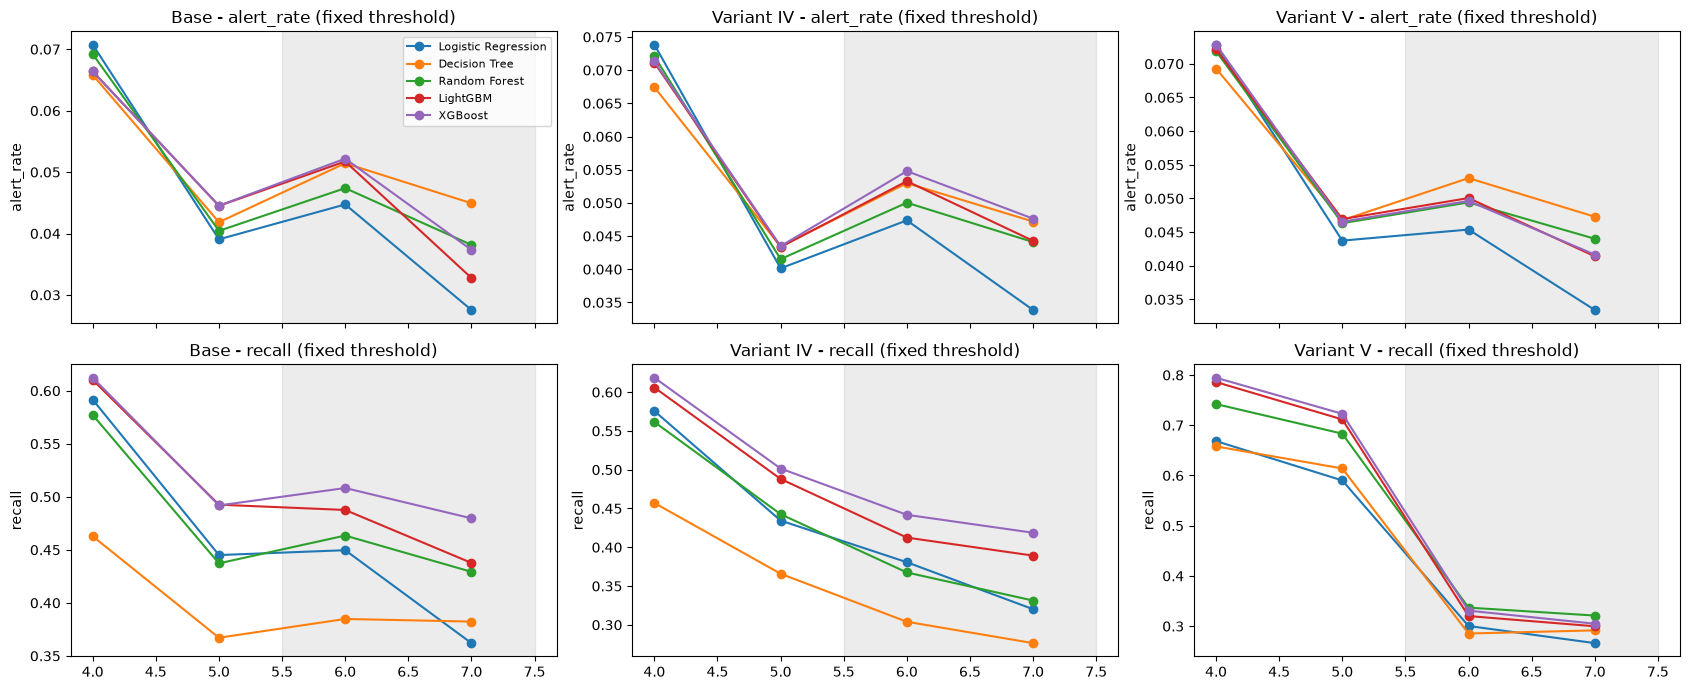

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 7), sharex=True)
for j, ds in enumerate(DATASETS):
    for i, met in enumerate(["alert_rate", "recall"]):
        ax = axes[i, j]
        for m in MODEL_NAMES:
            r = thr_month[(thr_month.dataset == ds) & (thr_month.model == m)]
            ax.plot(r.month, r[met], "-o", label=m)
        ax.axvspan(min(TEST_MONTHS) - 0.5, max(TEST_MONTHS) + 0.5, color="grey", alpha=0.15)
        ax.set(title=f"{ds} - {met} (fixed threshold)", ylabel=met)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

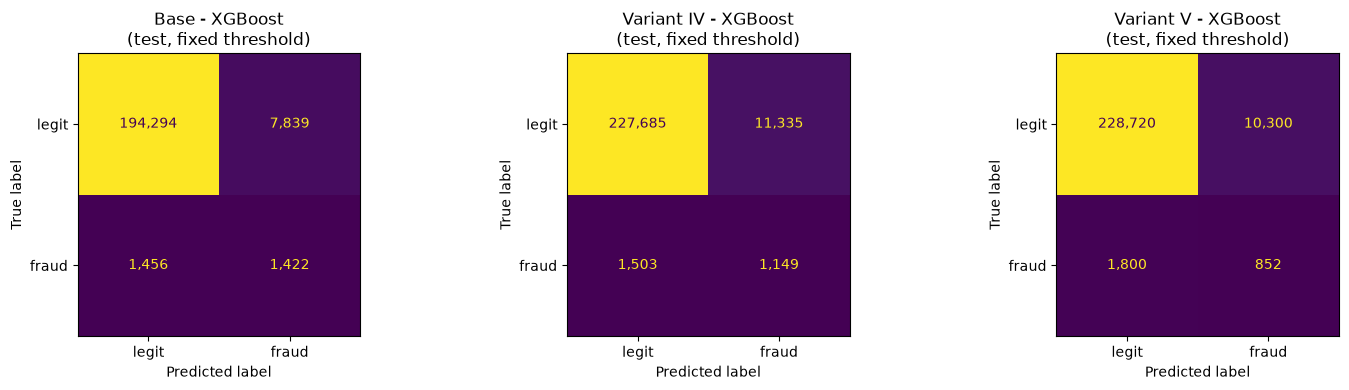

In [19]:
# Confusion matrices on the test period for the selected model
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, ds in zip(axes, DATASETS):
    g = preds[(preds.dataset == ds) & (preds.model == BEST) & (preds.split == "test")]
    ConfusionMatrixDisplay(confusion_matrix(g.y, g.flag_thr), display_labels=["legit", "fraud"]).plot(
        ax=ax, colorbar=False, values_format=",")
    ax.set_title(f"{ds} - {BEST}\n(test, fixed threshold)")
plt.tight_layout(); plt.show()

## 9. Operating setting B — fixed review capacity (secondary)
Each month, the highest-scoring 1% and 5% of applications are sent for review. Workload is constant and the threshold changes month to month. Only that month's scores are used (no labels), so there is no leakage.

In [20]:
n_month = preds.groupby(["dataset", "model", "month"]).score_tb.transform("size")
rank_in_month = preds.groupby(["dataset", "model", "month"]).score_tb.rank(method="first", ascending=False)
cap_tables = []
for cap in REVIEW_CAPACITIES:
    col = f"flag_cap{int(cap * 100)}"
    preds[col] = rank_in_month <= np.ceil(cap * n_month)
    cap_tables.append(summarise(preds, col, ["dataset", "model", "split"]).assign(capacity=cap))
cap_period = pd.concat(cap_tables, ignore_index=True)
display(cap_period.pivot_table(index=["dataset", "model"], columns=["capacity", "split"],
                               values=["recall", "FPR"]))
cap_period.to_csv(f"{OUT_DIR}/fixed_capacity_period.csv", index=False)

FPR                      recall         \
capacity                       0.0100        0.0500        0.0100          
split                            test    val   test    val   test    val   
dataset    model                                                           
Base       Decision Tree       0.0081 0.0084 0.0451 0.0458 0.1411 0.1509   
           LightGBM            0.0073 0.0074 0.0436 0.0444 0.2026 0.2295   
           Logistic Regression 0.0075 0.0078 0.0438 0.0447 0.1876 0.1998   
           Random Forest       0.0075 0.0078 0.0438 0.0449 0.1852 0.1970   
           XGBoost             0.0072 0.0074 0.0433 0.0443 0.2092 0.2323   
Variant IV Decision Tree       0.0089 0.0083 0.0474 0.0457 0.1075 0.1450   
           LightGBM            0.0083 0.0074 0.0461 0.0442 0.1595 0.2247   
           Logistic Regression 0.0085 0.0077 0.0462 0.0447 0.1474 0.1946   
           Random Forest       0.0086 0.0078 0.0465 0.0448 0.1342 0.1886   
           XGBoost             0.0082 0.0074 0.0459 0.0441 0.1686 0.2241   
Variant V  Decision Tree       0.0093 0.0054 0.0474 0.0432 0.0758 0.3842   
           LightGBM            0.0087 0.0043 0.0470 0.0417 0.1297 0.4723   
           Logistic Regression 0.0088 0.0061 0.0469 0.0432 0.1161 0.3291   
           Random Forest       0.0088 0.0048 0.0468 0.0422 0.1199 0.4293   
           XGBoost             0.0085 0.0043 0.0469 0.0417 0.1414 0.4723   

                                              
capacity                       0.0500         
split                            test    val  
dataset    model                              
Base       Decision Tree       0.3930 0.4129  
           LightGBM            0.5014 0.5264  
           Logistic Regression 0.4858 0.5019  
           Random Forest       0.4847 0.4859  
           XGBoost             0.5215 0.5341  
Variant IV Decision Tree       0.2839 0.3962  
           LightGBM            0.4054 0.5217  
           Logistic Regression 0.3895 0.4823  
           Random Forest       0.3650 0.4726  
           XGBoost             0.4219 0.5280  
Variant V  Decision Tree       0.2821 0.6068  
           LightGBM            0.3228 0.7238  
           Logistic Regression 0.3296 0.6053  
           Random Forest       0.3428 0.6859  
           XGBoost             0.3330 0.7286

## 10. Age-group comparison (≤50 vs >50)
**Primary analysis: fixed threshold.** This isolates how each model's scores behave for each group. The fixed-capacity results are a secondary check: under fixed capacity, if one group's scores rise, that group takes up more review slots, and both groups' rates shift as a result.

`FPR_ratio_>50/<=50` > 1 means older applicants are wrongly flagged more often.

In [21]:
age_thr = summarise(preds, "flag_thr", ["dataset", "model", "split", "age_group"])
gap_thr = age_gap(age_thr, ["dataset", "model", "split"])
print("PRIMARY - fixed threshold (5% FPR on validation)")
display(gap_thr)

gap_cap = {}
for cap in REVIEW_CAPACITIES:
    col = f"flag_cap{int(cap * 100)}"
    gap_cap[cap] = age_gap(summarise(preds, col, ["dataset", "model", "split", "age_group"]),
                           ["dataset", "model", "split"])
    print(f"\nSECONDARY - fixed capacity {cap:.0%}")
    display(gap_cap[cap])

gap_thr.to_csv(f"{OUT_DIR}/age_gap_fixed_threshold.csv")
pd.concat(gap_cap, names=["capacity"]).to_csv(f"{OUT_DIR}/age_gap_fixed_capacity.csv")

PRIMARY - fixed threshold (5% FPR on validation)


FPR_<=50  FPR_>50  recall_<=50  \
dataset    model               split                                   
Base       Decision Tree       test     0.0419   0.0863       0.3740   
                               val      0.0476   0.1042       0.4098   
           LightGBM            test     0.0335   0.1206       0.4351   
                               val      0.0453   0.1565       0.5244   
           Logistic Regression test     0.0287   0.0985       0.3748   
                               val      0.0457   0.1475       0.4917   
           Random Forest       test     0.0346   0.1034       0.4244   
                               val      0.0462   0.1365       0.4905   
           XGBoost             test     0.0356   0.1178       0.4672   
                               val      0.0452   0.1591       0.5248   
Variant IV Decision Tree       test     0.0413   0.0930       0.2547   
                               val      0.0432   0.0982       0.3969   
           LightGBM            test     0.0360   0.1106       0.3588   
                               val      0.0392   0.1264       0.5068   
           Logistic Regression test     0.0294   0.0973       0.3100   
                               val      0.0391   0.1269       0.4594   
           Random Forest       test     0.0372   0.0918       0.3155   
                               val      0.0421   0.1057       0.4837   
           XGBoost             test     0.0379   0.1141       0.3888   
                               val      0.0395   0.1243       0.5214   
Variant V  Decision Tree       test     0.0451   0.0675       0.2630   
                               val      0.0473   0.0687       0.6880   
           LightGBM            test     0.0359   0.0952       0.2486   
                               val      0.0415   0.1094       0.7812   
           Logistic Regression test     0.0303   0.0876       0.2430   
                               val      0.0406   0.1157       0.6640   
           Random Forest       test     0.0404   0.0684       0.2987   
                               val      0.0458   0.0795       0.7630   
           XGBoost             test     0.0353   0.0981       0.2514   
                               val      0.0407   0.1153       0.7841   

                                      recall_>50  FPR_ratio_>50/<=50  \
dataset    model               split                                   
Base       Decision Tree       test       0.4513              2.0592   
                               val        0.4531              2.1887   
           LightGBM            test       0.6574              3.6053   
                               val        0.7318              3.4544   
           Logistic Regression test       0.6267              3.4355   
                               val        0.6979              3.2269   
           Random Forest       test       0.6017              2.9854   
                               val        0.6224              2.9558   
           XGBoost             test       0.6825              3.3049   
                               val        0.7344              3.5212   
Variant IV Decision Tree       test       0.4699              2.2535   
                               val        0.4757              2.2738   
           LightGBM            test       0.6071              3.0696   
                               val        0.6805              3.2243   
           Logistic Regression test       0.5759              3.3075   
                               val        0.6592              3.2432   
           Random Forest       test       0.5281              2.4704   
                               val        0.5842              2.5077   
           XGBoost             test       0.6341              3.0133   
                               val        0.6897              3.1484   
Variant V  Decision Tree       test       0.3952              1.4961   
                               val        0.4125              1.4517   
     


SECONDARY - fixed capacity 1%


FPR_<=50  FPR_>50  recall_<=50  \
dataset    model               split                                   
Base       Decision Tree       test     0.0076   0.0221       0.1314   
                               val      0.0078   0.0207       0.1424   
           LightGBM            test     0.0062   0.0338       0.1790   
                               val      0.0063   0.0339       0.2077   
           Logistic Regression test     0.0066   0.0288       0.1683   
                               val      0.0066   0.0340       0.1803   
           Random Forest       test     0.0069   0.0226       0.1715   
                               val      0.0071   0.0245       0.1843   
           XGBoost             test     0.0063   0.0289       0.1894   
                               val      0.0063   0.0325       0.2106   
Variant IV Decision Tree       test     0.0073   0.0202       0.0843   
                               val      0.0067   0.0198       0.1266   
           LightGBM            test     0.0060   0.0249       0.1285   
                               val      0.0053   0.0219       0.1895   
           Logistic Regression test     0.0057   0.0281       0.1129   
                               val      0.0052   0.0256       0.1527   
           Random Forest       test     0.0070   0.0196       0.1096   
                               val      0.0066   0.0167       0.1698   
           XGBoost             test     0.0060   0.0240       0.1409   
                               val      0.0054   0.0214       0.1869   
Variant V  Decision Tree       test     0.0096   0.0069       0.0705   
                               val      0.0059   0.0016       0.4565   
           LightGBM            test     0.0073   0.0182       0.0955   
                               val      0.0038   0.0080       0.5431   
           Logistic Regression test     0.0065   0.0249       0.0918   
                               val      0.0045   0.0174       0.3604   
           Random Forest       test     0.0079   0.0149       0.0983   
                               val      0.0046   0.0064       0.4918   
           XGBoost             test     0.0071   0.0190       0.1058   
                               val      0.0037   0.0090       0.5366   

                                      recall_>50  FPR_ratio_>50/<=50  \
dataset    model               split                                   
Base       Decision Tree       test       0.2089              2.9121   
                               val        0.2057              2.6468   
           LightGBM            test       0.3677              5.4533   
                               val        0.3698              5.4054   
           Logistic Regression test       0.3231              4.3461   
                               val        0.3255              5.1269   
           Random Forest       test       0.2813              3.2709   
                               val        0.2786              3.4707   
           XGBoost             test       0.3482              4.5901   
                               val        0.3724              5.1674   
Variant IV Decision Tree       test       0.2121              2.7682   
                               val        0.1886              2.9355   
           LightGBM            test       0.2994              4.1668   
                               val        0.3083              4.1267   
           Logistic Regression test       0.3035              4.9673   
                               val        0.2941              4.9274   
           Random Forest       test       0.2453              2.7893   
                               val        0.2333              2.5396   
           XGBoost             test       0.2931              4.0152   
                               val        0.3124              3.9712   
Variant V  Decision Tree       test       0.0988              0.7155   
                               val        0.0399              0.2684   
     


SECONDARY - fixed capacity 5%


FPR_<=50  FPR_>50  recall_<=50  \
dataset    model               split                                   
Base       Decision Tree       test     0.0434   0.0872       0.3843   
                               val      0.0437   0.0913       0.4070   
           LightGBM            test     0.0400   0.1338       0.4764   
                               val      0.0401   0.1427       0.4974   
           Logistic Regression test     0.0406   0.1245       0.4561   
                               val      0.0408   0.1334       0.4768   
           Random Forest       test     0.0409   0.1166       0.4621   
                               val      0.0415   0.1214       0.4691   
           XGBoost             test     0.0400   0.1250       0.4966   
                               val      0.0399   0.1449       0.5067   
Variant IV Decision Tree       test     0.0405   0.0952       0.2409   
                               val      0.0393   0.0915       0.3666   
           LightGBM            test     0.0365   0.1128       0.3602   
                               val      0.0343   0.1143       0.4662   
           Logistic Regression test     0.0363   0.1157       0.3395   
                               val      0.0346   0.1162       0.4213   
           Random Forest       test     0.0393   0.0966       0.3252   
                               val      0.0379   0.0933       0.4388   
           XGBoost             test     0.0366   0.1105       0.3772   
                               val      0.0346   0.1114       0.4752   
Variant V  Decision Tree       test     0.0449   0.0653       0.2593   
                               val      0.0416   0.0542       0.6614   
           LightGBM            test     0.0390   0.1031       0.2560   
                               val      0.0347   0.0911       0.7543   
           Logistic Regression test     0.0383   0.1076       0.2815   
                               val      0.0349   0.1011       0.6367   
           Random Forest       test     0.0430   0.0729       0.3084   
                               val      0.0386   0.0673       0.7332   
           XGBoost             test     0.0383   0.1071       0.2616   
                               val      0.0340   0.0955       0.7561   

                                      recall_>50  FPR_ratio_>50/<=50  \
dataset    model               split                                   
Base       Decision Tree       test       0.4540              2.0061   
                               val        0.4505              2.0873   
           LightGBM            test       0.6769              3.3456   
                               val        0.7135              3.5606   
           Logistic Regression test       0.6936              3.0669   
                               val        0.6641              3.2703   
           Random Forest       test       0.6435              2.8498   
                               val        0.5938              2.9233   
           XGBoost             test       0.6964              3.1220   
                               val        0.7109              3.6309   
Variant IV Decision Tree       test       0.4782              2.3491   
                               val        0.4665              2.3280   
           LightGBM            test       0.6091              3.0937   
                               val        0.6531              3.3319   
           Logistic Regression test       0.6154              3.1907   
                               val        0.6268              3.3612   
           Random Forest       test       0.5447              2.4582   
                               val        0.5527              2.4595   
           XGBoost             test       0.6237              3.0207   
                               val        0.6531              3.2187   
Variant V  Decision Tree       test       0.3810              1.4538   
                               val        0.3466              1.3047   
     

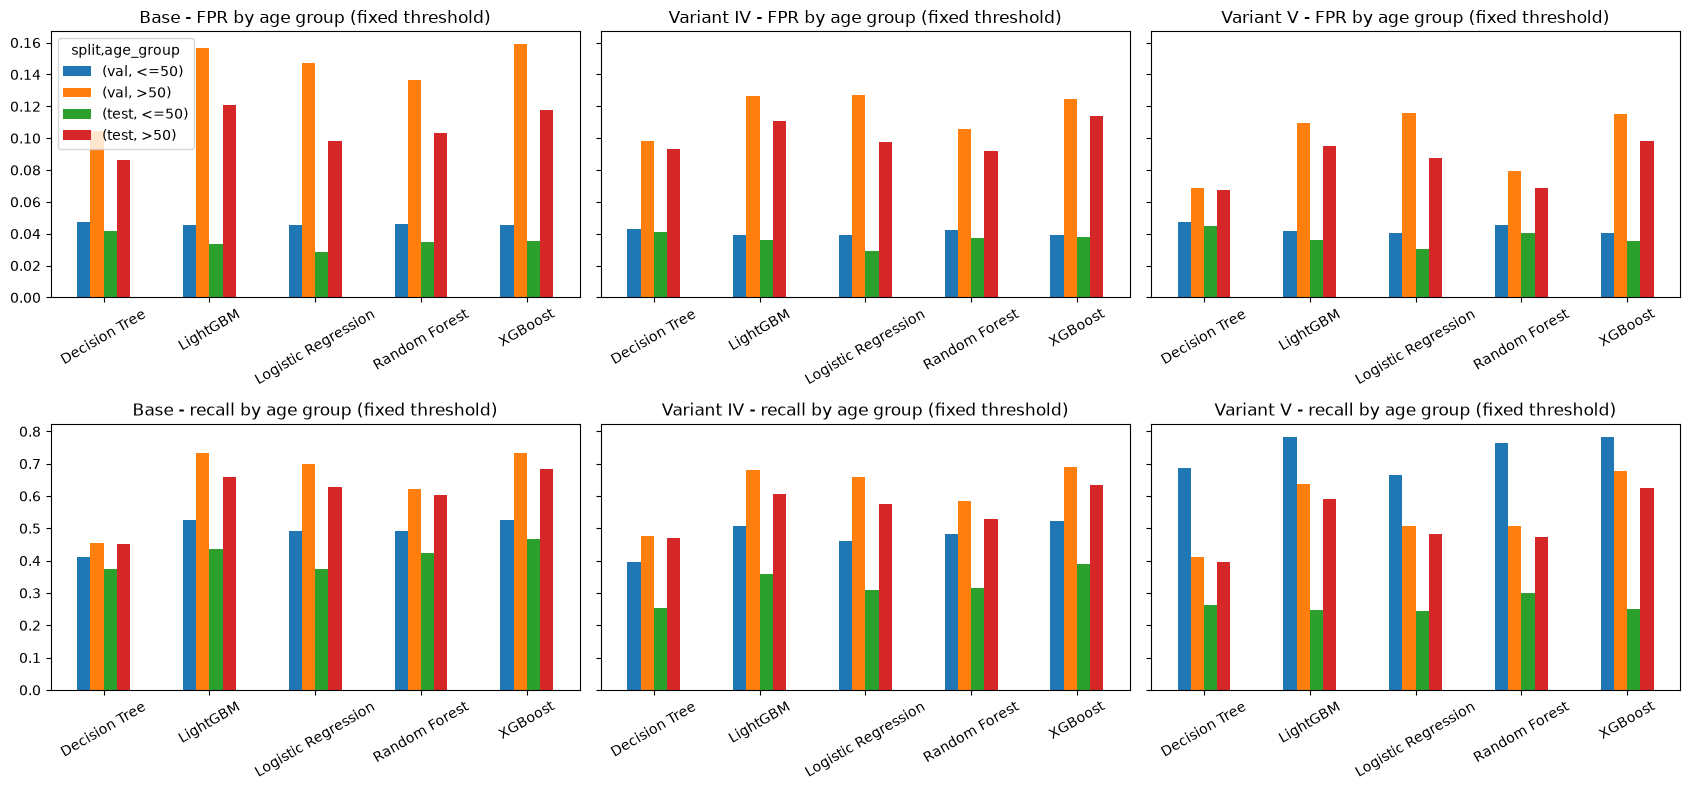

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharey="row")
for j, ds in enumerate(DATASETS):
    for i, met in enumerate(["FPR", "recall"]):
        ax = axes[i, j]
        t = age_thr[(age_thr.dataset == ds)].pivot_table(index="model", columns=["split", "age_group"], values=met)
        t = t.reindex(columns=[("val", "<=50"), ("val", ">50"), ("test", "<=50"), ("test", ">50")])
        t.plot.bar(ax=ax, rot=30, legend=(i == 0 and j == 0))
        ax.set(title=f"{ds} - {met} by age group (fixed threshold)", xlabel="")
plt.tight_layout(); plt.show()

## 11. Interpretation
### 11.1 Stability of feature predictiveness over time
For each numeric feature, univariate predictive strength = |2·AUC − 1| (0 = no signal, 1 = perfect separation), computed per month and age group. Variant V should show signals that fade in months 6–7 for one age group.

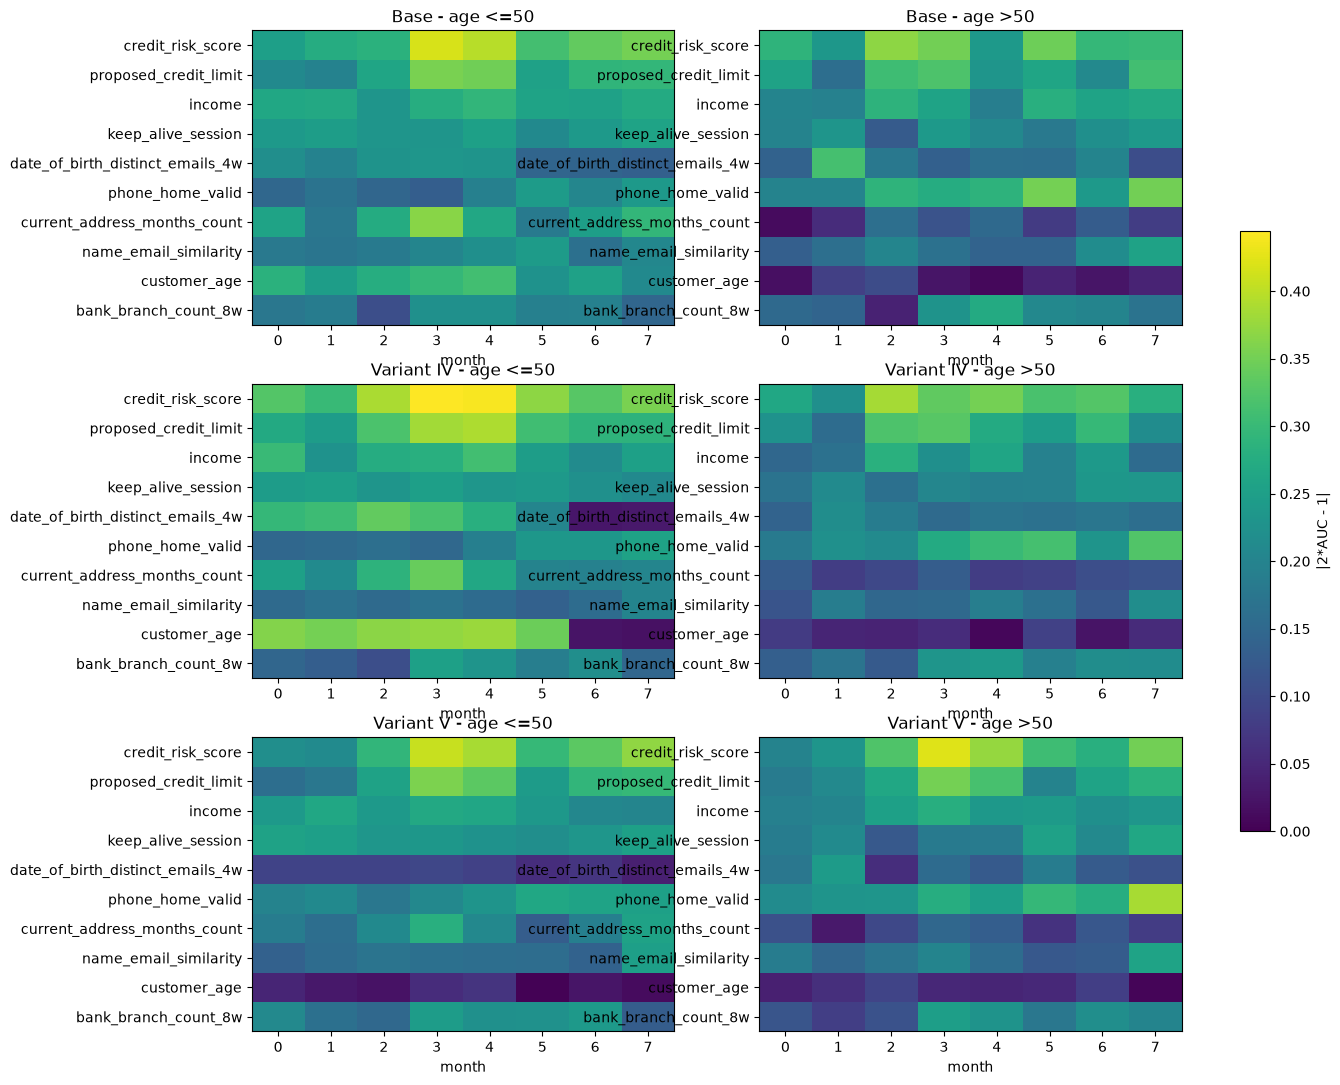

In [23]:
def univariate_strength(df, features):
    rows = []
    for (mo, ag), g in df.groupby([MONTH, "age_group"]):
        if g[TARGET].nunique() < 2:
            continue
        for c in features:
            x = g[c].fillna(g[c].median())
            rows.append({"month": mo, "age_group": ag, "feature": c,
                         "strength": abs(2 * roc_auc_score(g[TARGET], x) - 1)})
    return pd.DataFrame(rows)

_, _, nums_base = feature_lists(data["Base"][data["Base"].split == "train"])
strength = pd.concat([univariate_strength(df, nums_base).assign(dataset=ds) for ds, df in data.items()])
top_feats = (strength[(strength.dataset == "Base") & (strength.month.isin(TRAIN_MONTHS))]
             .groupby("feature").strength.mean().nlargest(10).index)

fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for i, ds in enumerate(DATASETS):
    for j, ag in enumerate(["<=50", ">50"]):
        h = (strength[(strength.dataset == ds) & (strength.age_group == ag) & strength.feature.isin(top_feats)]
             .pivot(index="feature", columns="month", values="strength").reindex(top_feats))
        im = axes[i, j].imshow(h.values, aspect="auto", cmap="viridis", vmin=0, vmax=strength.strength.max())
        axes[i, j].set(title=f"{ds} - age {ag}", xticks=range(h.shape[1]), xticklabels=h.columns,
                       yticks=range(len(h)), yticklabels=h.index, xlabel="month")
fig.colorbar(im, ax=axes, shrink=0.6, label="|2*AUC - 1|")
plt.show()

### 11.2 Permutation importance (selected model): validation vs test
Importance is measured as the drop in AP when a feature is shuffled, on a sample of each period. Features that matter on validation but not on test indicate reliance on unstable relationships.

In [24]:
PI_SAMPLE = 50_000
pi_rows = []
for ds, df in data.items():
    pipe, feats = fitted[(ds, BEST)]
    for sp in ["val", "test"]:
        part = df[df.split == sp]
        part = part.sample(min(PI_SAMPLE, len(part)), random_state=RANDOM_STATE)
        r = permutation_importance(pipe, part[feats], part[TARGET], scoring="average_precision",
                                   n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
        pi_rows += [{"dataset": ds, "split": sp, "feature": f, "importance": v}
                    for f, v in zip(feats, r.importances_mean)]
pi = pd.DataFrame(pi_rows).pivot_table(index=["dataset", "feature"], columns="split", values="importance")
pi["change"] = pi["test"] - pi["val"]
for ds in DATASETS:
    print(f"\n{ds} - top 10 features by validation importance ({BEST})")
    display(pi.loc[ds].sort_values("val", ascending=False).head(10))
pi.to_csv(f"{OUT_DIR}/permutation_importance.csv")


Base - top 10 features by validation importance (XGBoost)


split,test,val,change
feature,,,
device_os,0.0355,0.0427,-0.0072
housing_status,0.0459,0.0327,0.0132
has_other_cards,0.0192,0.0298,-0.0106
phone_home_valid,0.0360,0.0274,0.0085
name_email_similarity,0.0210,0.0213,-0.0003
proposed_credit_limit,0.0095,0.0204,-0.0109
credit_risk_score,0.0134,0.0197,-0.0063
email_is_free,0.0222,0.0163,0.0059
current_address_months_count,0.0101,0.0154,-0.0054



Variant IV - top 10 features by validation importance (XGBoost)


split,test,val,change
feature,,,
device_os,0.0252,0.0417,-0.0165
housing_status,0.0177,0.0323,-0.0146
customer_age,-0.0119,0.0272,-0.0391
phone_home_valid,0.0236,0.0248,-0.0012
has_other_cards,0.0132,0.0221,-0.0089
keep_alive_session,0.0137,0.0204,-0.0067
date_of_birth_distinct_emails_4w,0.0005,0.0180,-0.0175
credit_risk_score,0.0079,0.0178,-0.0099
name_email_similarity,0.0104,0.0172,-0.0069



Variant V - top 10 features by validation importance (XGBoost)


split,test,val,change
feature,,,
x1,-0.0003,0.3589,-0.3592
x2,-0.0084,0.3520,-0.3604
customer_age,-0.0036,0.1439,-0.1475
phone_home_valid,0.0168,0.0257,-0.0089
has_other_cards,0.0092,0.0199,-0.0106
device_os,0.0166,0.0182,-0.0016
housing_status,0.0212,0.0155,0.0057
name_email_similarity,0.0076,0.0141,-0.0065
income,0.0063,0.0133,-0.0070


### 11.3 Error analysis: frauds missed in the test period
Using the selected model at the fixed threshold, test-period frauds are split into caught vs missed, by age group, and their feature profiles are compared.

In [25]:
for ds, df in data.items():
    g = preds[(preds.dataset == ds) & (preds.model == BEST) & (preds.split == "test") & (preds.y == 1)]
    print(f"\n=== {ds} ===")
    display(g.groupby("age_group").flag_thr.agg(frauds="size", caught="sum", recall="mean"))
    feats_frauds = df.loc[g.row].assign(outcome=np.where(g.flag_thr.values, "caught", "missed"))
    display(feats_frauds.groupby("outcome")[list(top_feats)].median().T)


=== Base ===


,frauds,caught,recall
age_group,,,
<=50,2519,1177,0.4672
>50,359,245,0.6825


outcome,caught,missed
credit_risk_score,215.0000,162.0000
proposed_credit_limit,1000.0000,200.0000
income,0.9000,0.8000
keep_alive_session,0.0000,0.0000
date_of_birth_distinct_emails_4w,5.0000,7.0000
phone_home_valid,0.0000,0.0000
current_address_months_count,111.0000,75.0000
name_email_similarity,0.2443,0.3447
customer_age,40.0000,40.0000
bank_branch_count_8w,1.0000,8.5000



=== Variant IV ===


,frauds,caught,recall
age_group,,,
<=50,2171,844,0.3888
>50,481,305,0.6341


outcome,caught,missed
credit_risk_score,222.0000,170.0000
proposed_credit_limit,1000.0000,500.0000
income,0.9000,0.8000
keep_alive_session,0.0000,0.0000
date_of_birth_distinct_emails_4w,4.0000,7.0000
phone_home_valid,0.0000,0.0000
current_address_months_count,116.0000,85.0000
name_email_similarity,0.2413,0.3488
customer_age,50.0000,40.0000
bank_branch_count_8w,1.0000,7.0000



=== Variant V ===


,frauds,caught,recall
age_group,,,
<=50,2156,542,0.2514
>50,496,310,0.6250


outcome,caught,missed
credit_risk_score,228.0000,181.0000
proposed_credit_limit,1500.0000,500.0000
income,0.9000,0.8000
keep_alive_session,0.0000,0.0000
date_of_birth_distinct_emails_4w,3.0000,6.0000
phone_home_valid,0.0000,0.0000
current_address_months_count,123.0000,96.0000
name_email_similarity,0.2297,0.2952
customer_age,50.0000,40.0000
bank_branch_count_8w,1.0000,4.5000


## 12. Summary table
One row per dataset × model with the headline numbers for the report.

In [26]:
summary = (robust[["AP_val", "AP_test", "AP_change", "recall@5%FPR_val", "recall@5%FPR_test", "recall@5%FPR_change"]]
           .join(thr_period[thr_period.split == "test"].set_index(["dataset", "model"])
                 [["recall", "FPR", "alert_rate"]].add_prefix("thr_test_"))
           .join(gap_thr.xs("test", level="split")[["FPR_ratio_>50/<=50", "recall_diff_>50-<=50"]]
                 .add_prefix("age_test_")))
for cap in REVIEW_CAPACITIES:
    c = cap_period[(cap_period.capacity == cap) & (cap_period.split == "test")].set_index(["dataset", "model"])
    summary[f"cap{int(cap * 100)}_test_recall"] = c["recall"]
display(summary)
summary.to_csv(f"{OUT_DIR}/summary.csv")

AP_val  AP_test  AP_change  recall@5%FPR_val  \
dataset    model                                                               
Base       Decision Tree        0.0945   0.1050     0.0105            0.4156   
           LightGBM             0.1820   0.1827     0.0007            0.5522   
           Logistic Regression  0.1442   0.1585     0.0143            0.5194   
           Random Forest        0.1426   0.1615     0.0189            0.5082   
           XGBoost              0.1852   0.1928     0.0076            0.5529   
Variant IV Decision Tree        0.1005   0.0588    -0.0417            0.4203   
           LightGBM             0.1913   0.1086    -0.0827            0.5584   
           Logistic Regression  0.1600   0.0943    -0.0657            0.5187   
           Random Forest        0.1582   0.0853    -0.0729            0.5135   
           XGBoost              0.1969   0.1154    -0.0815            0.5713   
Variant V  Decision Tree        0.3923   0.0396    -0.3527            0.6402   
           LightGBM             0.5507   0.0649    -0.4858            0.7560   
           Logistic Regression  0.3441   0.0693    -0.2748            0.6369   
           Random Forest        0.4902   0.0730    -0.4172            0.7184   
           XGBoost              0.5544   0.0740    -0.4804            0.7656   

                                recall@5%FPR_test  recall@5%FPR_change  \
dataset    model                                                         
Base       Decision Tree                   0.4135              -0.0022   
           LightGBM                        0.5316              -0.0206   
           Logistic Regression             0.5007              -0.0187   
           Random Forest                   0.5122               0.0040   
           XGBoost                         0.5424              -0.0105   
Variant IV Decision Tree                   0.2986              -0.1216   
           LightGBM                        0.4253              -0.1330   
           Logistic Regression             0.4069              -0.1118   
           Random Forest                   0.3801              -0.1334   
           XGBoost                         0.4446              -0.1267   
Variant V  Decision Tree                   0.2892              -0.3510   
           LightGBM                        0.3314              -0.4246   
           Logistic Regression             0.3480              -0.2888   
           Random Forest                   0.3556              -0.3628   
           XGBoost                         0.3439              -0.4218   

                                thr_test_recall  thr_test_FPR  \
dataset    model                                                
Base       Decision Tree                 0.3836        0.0436   
           LightGBM                      0.4628        0.0368   
           Logistic Regression           0.4062        0.0314   
           Random Forest                 0.4465        0.0373   
           XGBoost                       0.4941        0.0388   
Variant IV Decision Tree                 0.2937        0.0477   
           LightGBM                      0.4038        0.0454   
           Logistic Regression           0.3582        0.0380   
           Random Forest                 0.3541        0.0440   
           XGBoost                       0.4333        0.0474   
Variant V  Decision Tree                 0.2877        0.0479   
           LightGBM                      0.3126        0.0433   
           Logistic Regression           0.2877        0.0374   
           Random Forest                 0.3311        0.0439   
           XGBoost                       0.3213        0.0431   

                                thr_test_alert_rate  \
dataset    model                                      
Base       Decision Tree                     0.0484   
           LightGBM                          0.0428   
           Logistic Regression               0.0366   
           Random Forest       

## Notes and limitations
* Scores are tie-broken with negligible random noise before thresholding (see section 5), so fixed-FPR and top-k rules behave sensibly for models with few distinct scores such as the decision tree.
* The BAF data are synthetic; results are controlled evidence about model behaviour under imbalance and temporal shift, not production performance estimates.
* The model used for testing is the one trained on months 0–3, so the validation-chosen threshold matches its scores exactly. Refitting on months 0–5 would use more data but would require re-deriving the threshold (e.g. by cross-fitting).
* Hyperparameters were chosen on a single time-respecting holdout (months 4–5 of Base); an expanding-window scheme is a possible extension.